In [163]:
import pandas as pd 
import numpy as np
import seaborn as sns 
import matplotlib.pyplot as plt
import sklearn

In [164]:
df=pd.read_csv(r"C:\Users\Hp\Downloads\Finance_Dashboard_40500_Messy_Records.csv")
df.head()

,Transaction_ID,Date,Department,Category,Region,Payment_Method,Budget_Amount,Actual_Amount,Revenue,Units,Discount_Pct,Tax_Pct
0,FIN100001,2022-01-01 00:00:00,Procurement,Marketing,North,Credit Card,27423.00,225455.12,157628.84,197,7.2,8.5
1,FIN100002,2022-01-01 00:52:33.678841971,Operations,Office Supplies,Central,Cheque,61448.86,105561.48,49310.81,180,10.4,12.9
2,FIN100003,2022-01-01 01:45:07.357683942,Procurement,Salaries,East,Cash,249419.97,156191.76,313816.45,90,23.2,17.1
3,FIN100004,2022-01-01 02:37:41.036525913,IT,Office Supplies,East,Cash,109126.61,50701.28,35172.60,36,8.5,13.7
4,FIN100005,2022-01-01 03:30:14.715367884,HR,Office Supplies,Central,Cash,14408.68,90050.36,482360.26,144,27.2,10.8


In [165]:
df.shape

(40500, 12)

In [166]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40500 entries, 0 to 40499
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Transaction_ID  40500 non-null  object 
 1   Date            40399 non-null  object 
 2   Department      40374 non-null  object 
 3   Category        40369 non-null  object 
 4   Region          40374 non-null  object 
 5   Payment_Method  40375 non-null  object 
 6   Budget_Amount   40249 non-null  float64
 7   Actual_Amount   40249 non-null  float64
 8   Revenue         40244 non-null  float64
 9   Units           40500 non-null  int64  
 10  Discount_Pct    40249 non-null  float64
 11  Tax_Pct         40246 non-null  float64
dtypes: float64(5), int64(1), object(6)
memory usage: 3.7+ MB


# 1. Type Casting

In [167]:
df["Date"] = df["Date"] = pd.to_datetime(df['Date'],errors = 'coerce')

**We convert Date from text (object) to datetime64 to enable date filtering and time-series analysis**

In [168]:
# checking for the data types
df.dtypes

Transaction_ID            object
Date              datetime64[ns]
Department                object
Category                  object
Region                    object
Payment_Method            object
Budget_Amount            float64
Actual_Amount            float64
Revenue                  float64
Units                      int64
Discount_Pct             float64
Tax_Pct                  float64
dtype: object

# 2. Noisy or Inconsistent

In [169]:
# check noise or inconsistent data 
for col in df.columns:
    print(col)
    print(df[col].unique())

Transaction_ID
['FIN100001' 'FIN100002' 'FIN100003' ... 'FIN139998' 'FIN139999'
 'FIN140000']
Date
<DatetimeArray>
['2022-01-01 00:00:00',                 'NaT', '2023-05-02 16:00:00',
 '2024-08-31 08:00:00', '2025-12-31 00:00:00']
Length: 5, dtype: datetime64[ns]
Department
['Procurement' 'Operations' 'IT' 'HR' 'Procurement ' 'Marketing' 'Finance'
 'Sales' 'Administration' 'finance' 'hr' nan 'Administration '
 'PROCUREMENT' 'IT ' 'MARKETING' 'operations' 'ADMINISTRATION' 'Sales '
 'HR ' 'OPERATIONS' 'Finance ' 'FINANCE' 'procurement' 'sales' 'it'
 'Marketing ' 'administration' 'SALES' 'Operations ' 'marketing']
Category
['Marketing' 'Office Supplies' 'Salaries' 'Rent' 'Software' 'Equipment'
 'Training' 'Utilities' 'Travel' 'Consulting' nan 'Marketing '
 'Office Supplies ' 'Utilities ' 'Salaries ' 'equipment' 'RENT' 'training'
 'TRAVEL' 'utilities' 'TRAINING' 'Equipment ' 'marketing' 'SALARIES'
 'software' 'MARKETING' 'Training ' 'SOFTWARE' 'CONSULTING'
 'OFFICE SUPPLIES' 'travel' 'con

**The .str.strip() function removes all extra leading (front) and trailing (back) spaces or unwanted characters from text strings in a pandas column.**

In [170]:
df['Department'] = df['Department'].str.strip()

In [171]:
df['Category'] = df['Category'].str.strip()

In [172]:
df['Region'] = df['Region'].str.strip()

In [173]:
df['Payment_Method'] = df['Payment_Method'].str.strip()

**The .str.title() function converts the first letter of each word in a string column to uppercase and all remaining letters to lowercase**

In [174]:
df['Department'] = df['Department'].str.title()

In [175]:
df['Category'] = df['Category'].str.title()

In [176]:
df['Region'] = df['Region'].str.title()

In [177]:
df['Payment_Method'] = df['Payment_Method'].str.title()

**This code corrects lowercase acronyms created by .str.title() back to standard uppercase format**

In [178]:
acronyms = {'Hr': 'HR', 'It': 'IT'}
df['Department'] = df['Department'].replace(acronyms)

In [179]:
acronyms = {'Upi': 'UPI'}
df['Payment_Method'] = df['Payment_Method'].replace(acronyms)

In [180]:
# check noise or inconsistent data are present or not
for col in df.columns:
    print(col)
    print(df[col].unique())

Transaction_ID
['FIN100001' 'FIN100002' 'FIN100003' ... 'FIN139998' 'FIN139999'
 'FIN140000']
Date
<DatetimeArray>
['2022-01-01 00:00:00',                 'NaT', '2023-05-02 16:00:00',
 '2024-08-31 08:00:00', '2025-12-31 00:00:00']
Length: 5, dtype: datetime64[ns]
Department
['Procurement' 'Operations' 'IT' 'HR' 'Marketing' 'Finance' 'Sales'
 'Administration' nan]
Category
['Marketing' 'Office Supplies' 'Salaries' 'Rent' 'Software' 'Equipment'
 'Training' 'Utilities' 'Travel' 'Consulting' nan]
Region
['North' 'Central' 'East' 'South' 'West' nan]
Payment_Method
['Credit Card' 'Cheque' 'Cash' 'Bank Transfer' 'UPI' nan]
Budget_Amount
[ 27423.    61448.86 249419.97 ...  85120.39 240203.09 110940.75]
Actual_Amount
[225455.12 105561.48 156191.76 ...  22169.47 155288.01 126336.67]
Revenue
[157628.84  49310.81 313816.45 ... 437110.35 465674.32 284670.08]
Units
[197 180  90  36 144  13 141  14  45 100 172  85  63 162  96   2 193  40
 194 125  16 102  80  39 163 127  43  53 191  82  84  58 129 1

# 3. Missing values

In [181]:
# Calculate count and percentage of missing values
missing_count = df.isnull().sum()
missing_percent = (df.isnull().sum() / len(df)) * 100

# Combine into a clean DataFrame
missing_summary = pd.DataFrame({
    'Missing_Count': missing_count,
    'Missing_Percentage (%)': missing_percent.round(2)
}).sort_values(by='Missing_Percentage (%)')

print(missing_summary)

                Missing_Count  Missing_Percentage (%)
Transaction_ID              0                    0.00
Units                       0                    0.00
Department                126                    0.31
Region                    126                    0.31
Payment_Method            125                    0.31
Category                  131                    0.32
Budget_Amount             251                    0.62
Actual_Amount             251                    0.62
Discount_Pct              251                    0.62
Revenue                   256                    0.63
Tax_Pct                   254                    0.63
Date                    40496                   99.99


**calculates and displays the total count and percentage of missing (NaN) values for Better Analysis**

In [182]:
# 1. Numerical Columns: Fill missing values with Median

num_cols = ['Budget_Amount', 'Actual_Amount', 'Revenue', 'Discount_Pct', 'Tax_Pct']

for col in num_cols:
    df[col] = df[col].fillna(df[col].median())

# 2. Categorical Columns: Fill missing value using mode function 
 
cat_cols = ['Department', 'Category', 'Region', 'Payment_Method']

for col in cat_cols:
    
    df[col] = df[col].fillna(df[col].mode()[0])

# 3. Date Column: Forward Fill or Backword fill
# This code fills missing dates (NaN/NaT) by copying the nearest available date—first from the previous row (ffill), and then from the next row (bfill) for any remaining gaps.
df['Date'] = df['Date'].ffill().bfill()

In [183]:
# check missing values clean
df.isna().sum()

Transaction_ID    0
Date              0
Department        0
Category          0
Region            0
Payment_Method    0
Budget_Amount     0
Actual_Amount     0
Revenue           0
Units             0
Discount_Pct      0
Tax_Pct           0
dtype: int64

# 4. Duplicates

In [184]:
total_rows = len(df)

# Calculate Duplicate Count and Percentage
dup_counts = total_rows - df.nunique(dropna=False)
dup_percentages = (dup_counts / total_rows) * 100

# Create formatted Summary DataFrame
dup_summary = pd.DataFrame({
    'Duplicate_Count': dup_counts,
    'Duplicate_Percentage (%)': dup_percentages.round(2)
}).sort_values(by='Duplicate_Count')

# Print in the exact table layout
print(dup_summary)

                Duplicate_Count  Duplicate_Percentage (%)
Transaction_ID              500                      1.23
Revenue                     766                      1.89
Actual_Amount               777                      1.92
Budget_Amount               787                      1.94
Discount_Pct              40199                     99.26
Units                     40301                     99.51
Tax_Pct                   40369                     99.68
Category                  40490                     99.98
Department                40492                     99.98
Region                    40495                     99.99
Payment_Method            40495                     99.99
Date                      40496                     99.99


In [185]:
df.duplicated().sum()

np.int64(0)

**it's not present measure duplicate**

# 5. Outliers

##### step 1  to using df.describe() to detect the outlier


In [186]:
df.describe()

,Date,Budget_Amount,Actual_Amount,Revenue,Units,Discount_Pct,Tax_Pct
count,40500,40500.000000,4.050000e+04,4.050000e+04,40500.000000,40500.000000,40500.000000
mean,2023-05-14 16:58:18.666666752,126927.480603,1.415931e+05,2.565382e+05,100.327654,15.093284,11.505064
min,2022-01-01 00:00:00,5016.470000,3.004150e+03,1.000466e+04,1.000000,0.000000,5.000000
25%,2022-01-01 00:00:00,65909.717500,7.252146e+04,1.326669e+05,51.000000,7.800000,8.300000
50%,2023-05-02 16:00:00,126470.750000,1.409544e+05,2.558962e+05,100.000000,15.100000,11.500000
75%,2024-08-31 08:00:00,187912.840000,2.085703e+05,3.784289e+05,150.000000,22.500000,14.700000
max,2025-12-31 00:00:00,249979.730000,1.874459e+06,2.636094e+06,199.000000,30.000000,18.000000
std,NaN,70523.078867,8.857961e+04,1.477829e+05,57.404096,8.626401,3.728944


##### step 2 using IQR method to find lower or upper bound


In [187]:
numeric_cols = df.select_dtypes(include='number').columns

for col in numeric_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    
    IQR = Q3 - Q1
    
    LB = Q1 - 1.5 * IQR
    UB = Q3 + 1.5 * IQR
    
    outliers = df[(df[col] < LB) | (df[col] > UB)]
    
    print("Column:", col)
    print("Q1:", Q1)
    print("Q3:", Q3)
    print("IQR:", IQR)
    print("Lower Bound:", LB)
    print("Upper Bound:", UB)
    print("Number of Outliers:", len(outliers))
    print("-" * 50)

Column: Budget_Amount
Q1: 65909.7175
Q3: 187912.84000000003
IQR: 122003.12250000003
Lower Bound: -117094.96625000003
Upper Bound: 370917.52375000005
Number of Outliers: 0
--------------------------------------------------
Column: Actual_Amount
Q1: 72521.465
Q3: 208570.315
IQR: 136048.85
Lower Bound: -131551.81000000003
Upper Bound: 412643.59
Number of Outliers: 68
--------------------------------------------------
Column: Revenue
Q1: 132666.90749999997
Q3: 378428.86
IQR: 245761.9525
Lower Bound: -235976.02125000005
Upper Bound: 747071.7887500001
Number of Outliers: 39
--------------------------------------------------
Column: Units
Q1: 51.0
Q3: 150.0
IQR: 99.0
Lower Bound: -97.5
Upper Bound: 298.5
Number of Outliers: 0
--------------------------------------------------
Column: Discount_Pct
Q1: 7.8
Q3: 22.5
IQR: 14.7
Lower Bound: -14.249999999999996
Upper Bound: 44.55
Number of Outliers: 0
--------------------------------------------------
Column: Tax_Pct
Q1: 8.3
Q3: 14.7
IQR: 6.3999999

##### display outliers using box plot for better analysis

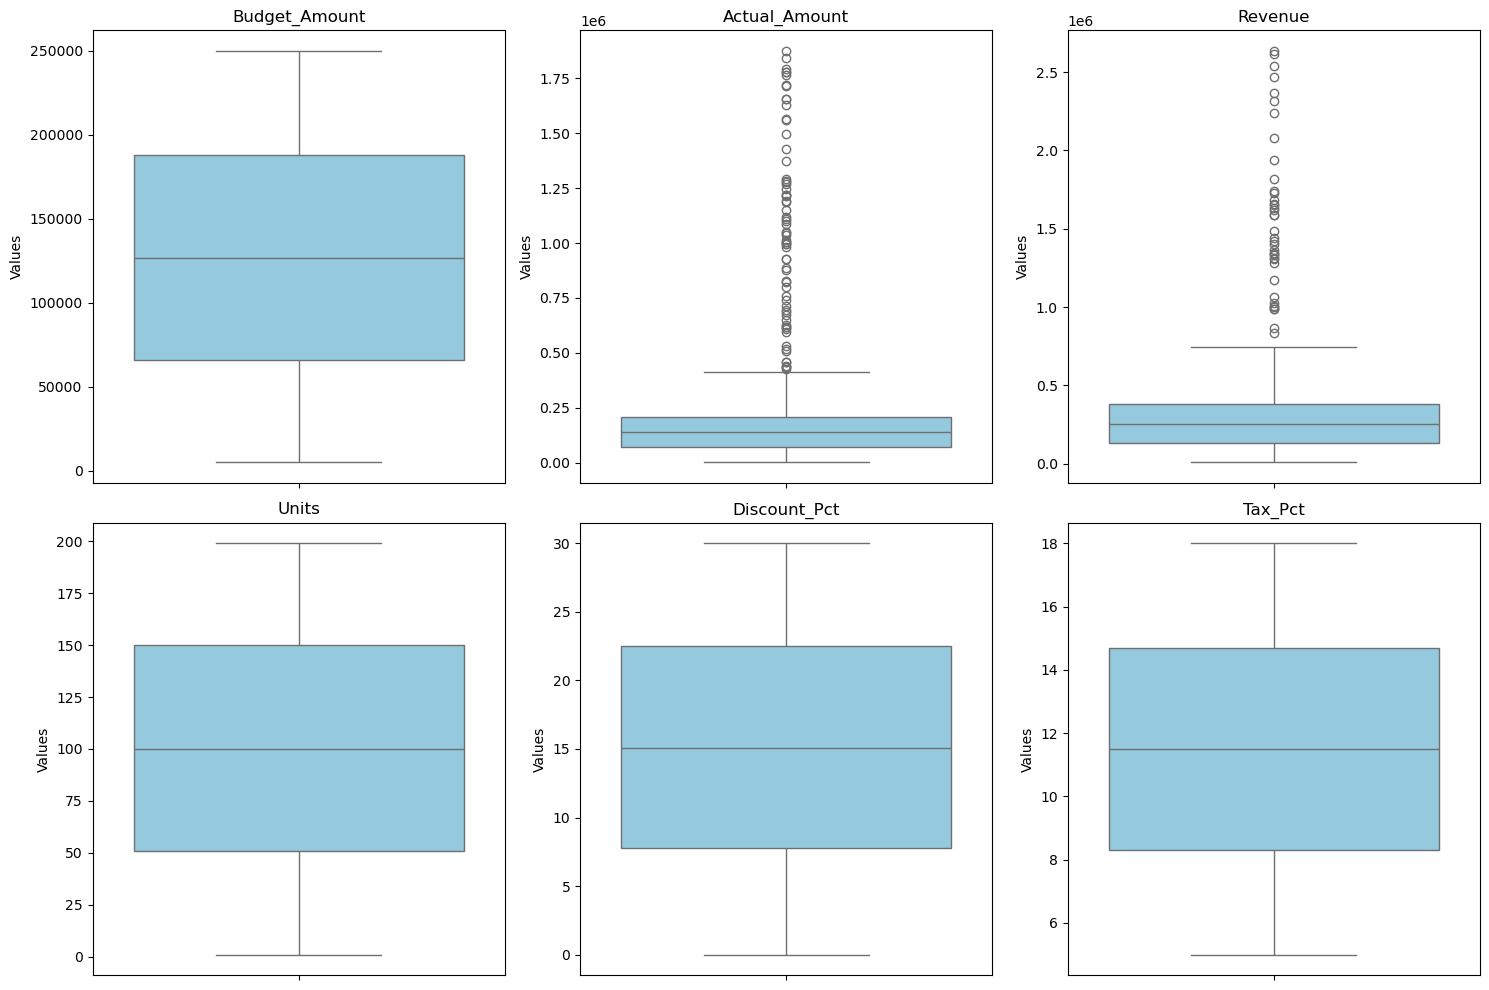

In [188]:
num_cols = ['Budget_Amount', 'Actual_Amount', 'Revenue', 'Units', 'Discount_Pct', 'Tax_Pct']

plt.figure(figsize=(15, 10))

for i, col in enumerate(num_cols, 1):
    plt.subplot(2, 3, i)
    sns.boxplot(y=df[col], color='skyblue')
    plt.title(col)
    plt.ylabel('Values')

plt.tight_layout()
plt.show()

##### Calculating outliers Count and Percentage for easy to detect outliers present in dataset 


In [189]:
num_cols = ['Budget_Amount', 'Actual_Amount', 'Revenue', 'Units', 'Discount_Pct', 'Tax_Pct']

outlier_data = {}

for col in num_cols:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    
    # Box Plot चे Whisker Limits (Lower and Upper Bounds)
    lower_whisker = q1 - 1.5 * iqr
    upper_whisker = q3 + 1.5 * iqr
    
    # Whisker च्या बाहेर असणारे बिंदू (Outliers)
    outliers = df[(df[col] < lower_whisker) | (df[col] > upper_whisker)][col]
    
    outlier_count = outliers.count()
    outlier_pct = round((outlier_count / len(df)) * 100, 2)
    
    outlier_data[col] = {
        'Outlier_Count': outlier_count,
        'Outlier_Percentage (%)': outlier_pct
    }

# डेटाफ्रेम बनवून टेबल फॉरमॅटमध्ये प्रिंट करणे
outlier_df = pd.DataFrame.from_dict(outlier_data, orient='index')
outlier_df.sort_values(by='Outlier_Count', inplace=True)

print(outlier_df)

               Outlier_Count  Outlier_Percentage (%)
Budget_Amount              0                    0.00
Units                      0                    0.00
Discount_Pct               0                    0.00
Tax_Pct                    0                    0.00
Revenue                   39                    0.10
Actual_Amount             68                    0.17


#### 1. Why shouldn't Outliers be removed from the revenue column?
**Because they are very few, represent valid high-value business transactions, and removing them could reduce the actual Total Revenue and affect the accuracy of the analysis**

#### 2. Why shouldn't Outliers be removed from the Actual_Amount  column?
**Because they are very few, may represent valid high-value financial transactions, and removing them could make the Total Expense/Actual Spending inaccurate**

# Datavisualization

### 1- Univariate analysis

In [190]:
df

,Transaction_ID,Date,Department,Category,Region,Payment_Method,Budget_Amount,Actual_Amount,Revenue,Units,Discount_Pct,Tax_Pct
0,FIN100001,2022-01-01,Procurement,Marketing,North,Credit Card,27423.00,225455.12,157628.84,197,7.2,8.5
1,FIN100002,2022-01-01,Operations,Office Supplies,Central,Cheque,61448.86,105561.48,49310.81,180,10.4,12.9
2,FIN100003,2022-01-01,Procurement,Salaries,East,Cash,249419.97,156191.76,313816.45,90,23.2,17.1
3,FIN100004,2022-01-01,IT,Office Supplies,East,Cash,109126.61,50701.28,35172.60,36,8.5,13.7
4,FIN100005,2022-01-01,HR,Office Supplies,Central,Cash,14408.68,90050.36,482360.26,144,27.2,10.8
...,...,...,...,...,...,...,...,...,...,...,...,...
40495,FIN113322,2025-12-31,Procurement,Travel,Central,Credit Card,126329.75,5123.29,283270.06,61,24.0,8.2
40496,FIN109674,2025-12-31,Sales,Software,West,Bank Transfer,124993.31,87248.49,244245.78,194,19.6,10.1
40497,FIN122032,2025-12-31,IT,Training,Central,UPI,142074.01,37088.04,203840.41,122,1.6,5.7
40498,FIN108354,2025-12-31,Sales,Utilities,East,Cheque,220453.92,231633.70,313344.60,71,18.0,11.6


In [191]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40500 entries, 0 to 40499
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   Transaction_ID  40500 non-null  object        
 1   Date            40500 non-null  datetime64[ns]
 2   Department      40500 non-null  object        
 3   Category        40500 non-null  object        
 4   Region          40500 non-null  object        
 5   Payment_Method  40500 non-null  object        
 6   Budget_Amount   40500 non-null  float64       
 7   Actual_Amount   40500 non-null  float64       
 8   Revenue         40500 non-null  float64       
 9   Units           40500 non-null  int64         
 10  Discount_Pct    40500 non-null  float64       
 11  Tax_Pct         40500 non-null  float64       
dtypes: datetime64[ns](1), float64(5), int64(1), object(5)
memory usage: 3.7+ MB


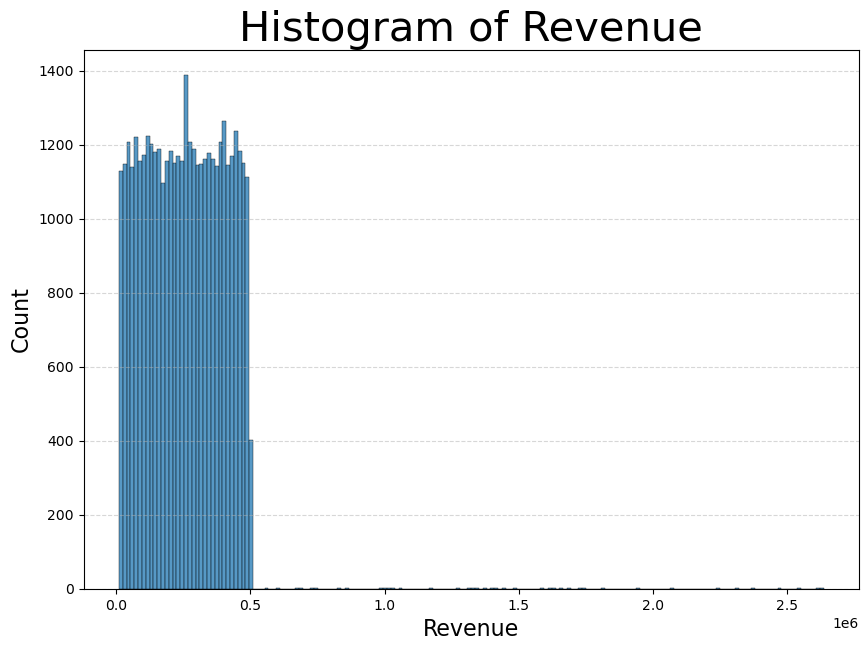

In [195]:
plt.figure(figsize=(10,7))
sns.histplot(data=df,x='Revenue')
plt.title('Histogram of Revenue', size = 30)
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.xlabel('Revenue', fontsize = 16)
plt.ylabel('Count', fontsize = 16)
plt.show()

### 2- Bivariate analysis

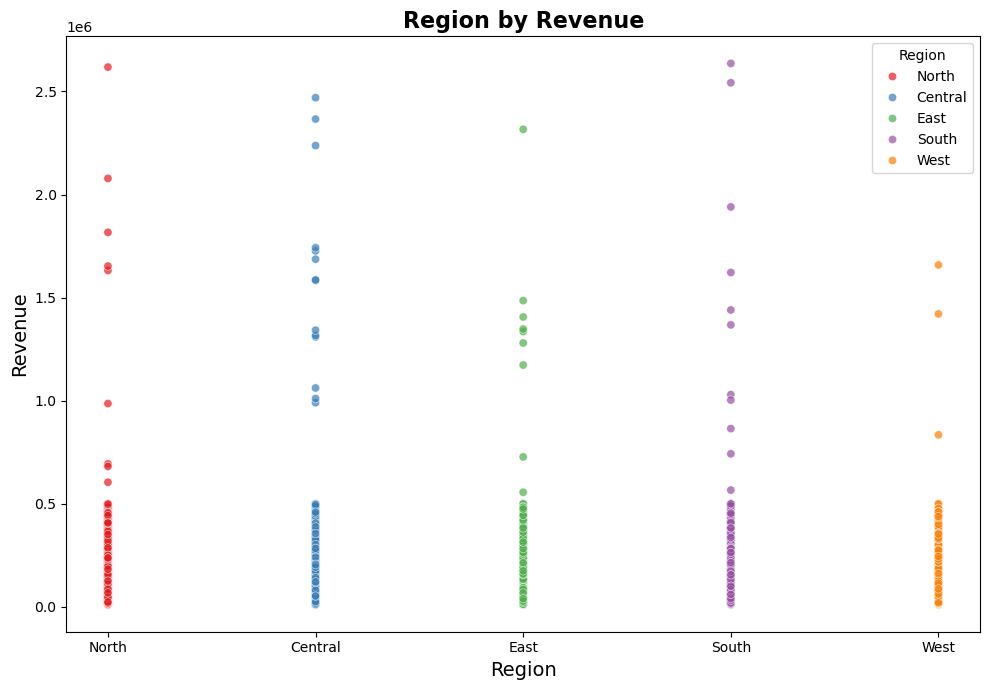

In [193]:
plt.figure(figsize=(10,7))

sns.scatterplot(
    data=df,
    y='Revenue',
    x='Region',
    hue = 'Region',
    palette='Set1',
    alpha=0.7
)
plt.title('Region by Revenue', fontsize=16, fontweight='bold')
plt.xlabel('Region', fontsize = 14)
plt.ylabel('Revenue', fontsize = 14)
plt.tight_layout()
plt.show()

### 3- Multivariate analysis

<Figure size 1400x900 with 0 Axes>

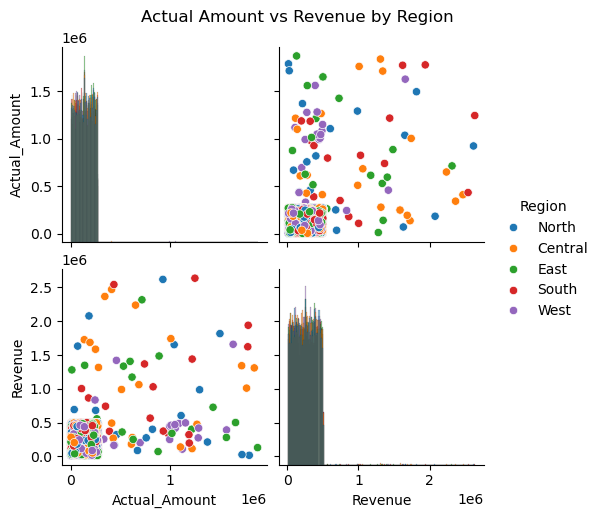

In [194]:
plt.figure(figsize=(14,9))
sns.pairplot(
    df,
    vars=['Actual_Amount', 'Revenue'],
    hue='Region',
    diag_kind='hist'
)

plt.suptitle('Actual Amount vs Revenue by Region', y=1.02)
plt.show()

In [196]:
df.to_csv(
    r"C:\Users\Hp\Arbor jupyter\ Saurabh\Project\Finance dataset.csv",
    index=False
)